In [1]:
!pip install --upgrade pip
!pip install ruptures
!pip install pytorch-lightning pytorch-forecasting
!pip install scikit-learn matplotlib
!sudo apt install ffmpeg
!pip install networkx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 36.5 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 39.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.1/823.1 kB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 52.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 53.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 58.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 33.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 72.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 76

In [2]:
#Core Analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from google.colab import drive
from scipy.stats import chi2_contingency
import seaborn as sns
import networkx as nx
from matplotlib.animation import FuncAnimation
import matplotlib.animation as animation
from sklearn.metrics import silhouette_score, mean_absolute_error

# 1) Data Loading & Preparation
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/comments_new.csv', parse_dates=["date_time"])
df.set_index('date_time', inplace=True)

# 2) Hourly Analysis & Clustering
hourly = df['sentiment_intensity'].resample('H').mean().ffill()

# Diurnal pattern heatmap
hourly_df = hourly.reset_index()
hourly_df['hour'] = hourly_df['date_time'].dt.hour
pivot = hourly_df.pivot_table(index='hour', columns=hourly_df['date_time'].dt.date, values='sentiment_intensity')

# Cluster daily profiles
profiles = pivot.T.ffill(axis=1).bfill(axis=1)
X = SimpleImputer(strategy='mean').fit_transform(profiles)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
kmeans = KMeans(n_clusters=2, random_state=42).fit(X_scaled)
centroids_orig = scaler.inverse_transform(kmeans.cluster_centers_)

# 3) LSTM Forecasting
values = hourly.values.reshape(-1,1)
scaler2 = StandardScaler()
scaled = scaler2.fit_transform(values)

T = 24
X_seq, y_seq = [], []
for i in range(len(scaled)-T):
    X_seq.append(scaled[i:i+T])
    y_seq.append(scaled[i+T])
X_seq, y_seq = np.array(X_seq), np.array(y_seq)

split = int(0.8*len(X_seq))
X_tr, X_te = X_seq[:split], X_seq[split:]
y_tr, y_te = y_seq[:split], y_seq[split:]

d_model = Sequential([
    LSTM(32, input_shape=(T,1)),
    Dense(1)
])
d_model.compile('adam', 'mse')
d_model.fit(X_tr, y_tr, epochs=20, batch_size=16, verbose=0)

pred = d_model.predict(X_te).flatten()
idx_te = hourly.index[T+split:T+split+len(pred)]

Mounted at /content/drive


<ipython-input-2-69aa07054c73>:24: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  hourly = df['sentiment_intensity'].resample('H').mean().ffill()
/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step


In [3]:
# Analysis Functions

def create_emotion_transition_matrix(df):
    emotions = df['emotion_code'].dropna().astype(str)
    unique_emotions = sorted(emotions.unique())
    trans_matrix = pd.DataFrame(0, index=unique_emotions, columns=unique_emotions)

    for prev, curr in zip(emotions[:-1], emotions[1:]):
        trans_matrix.loc[prev, curr] += 1

    return trans_matrix.div(trans_matrix.sum(axis=1), axis=0)

def analyze_topic_emotion_association(df):
    contingency = pd.crosstab(df['topic'], df['emotion_code'])
    chi2, p, _, _ = chi2_contingency(contingency)
    return {
        'chi2_stat': chi2,
        'p_value': p,
        'association_matrix': contingency.div(contingency.sum(axis=1), axis=0)
    }

def comprehensive_evaluation(df):
    results = {}
    trans_matrix = create_emotion_transition_matrix(df)
    results['transition_entropy'] = trans_matrix.apply(lambda x: -(x*np.log(x)).sum()).mean()

    profiles = pivot.T.ffill(axis=1).bfill(axis=1)
    X = StandardScaler().fit_transform(SimpleImputer().fit_transform(profiles))
    results['cluster_silhouette'] = silhouette_score(X, kmeans.labels_)

    results['lstm_mae'] = mean_absolute_error(
        scaler2.inverse_transform(y_te.reshape(-1,1)),
        scaler2.inverse_transform(pred.reshape(-1,1))
    )

    results.update(analyze_topic_emotion_association(df))
    return results

In [4]:
# First Visualization Set

def visualize_part1(df):
    fig, axs = plt.subplots(1, 2, figsize=(18, 6))

    # Heatmap
    sns.heatmap(pivot, ax=axs[0], cmap='coolwarm', cbar_kws={'label': 'Sentiment Intensity'})
    axs[0].set_title('Hourly Sentiment Heatmap', pad=15)

    # Emotion Transitions
    sns.heatmap(trans_matrix, annot=True, fmt=".2f", cmap="YlGnBu", ax=axs[1])
    axs[1].set_title("Emotion Transition Probabilities", pad=15)

    plt.tight_layout()
    plt.show()

In [5]:
# Second Visualization Set

def visualize_part2(df):
    fig, axs = plt.subplots(1, 2, figsize=(18, 6))

    # Temporal Distribution
    df.resample('12H')['emotion_code'].value_counts().unstack().plot.area(ax=axs[0])
    axs[0].set_title("Emotion Dynamics Timeline", pad=15)
    axs[0].legend(title='Emotion', bbox_to_anchor=(1.1, 1))

    # Forecasting Results
    axs[1].plot(idx_te, scaler2.inverse_transform(y_te.reshape(-1,1)), label='Actual')
    axs[1].plot(idx_te, scaler2.inverse_transform(pred.reshape(-1,1)), label='Forecast')
    axs[1].set_title(f"Forecast MAE: {mean_absolute_error(y_te, pred):.3f}", pad=15)
    axs[1].legend()

    plt.tight_layout()
    plt.show()



=== Part 1: Temporal Patterns ===


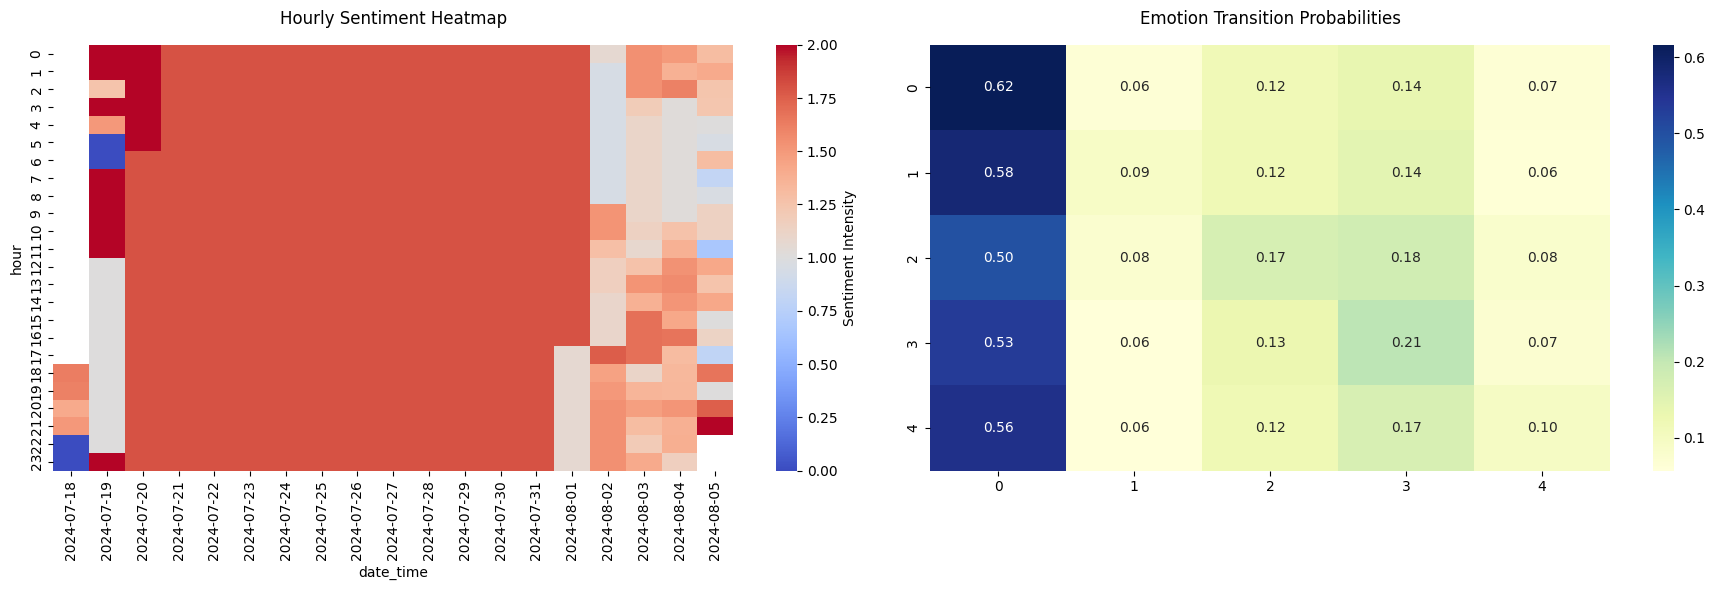


=== Part 2: Emotion Dynamics ===


<ipython-input-5-e51e684f6896>:7: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df.resample('12H')['emotion_code'].value_counts().unstack().plot.area(ax=axs[0])


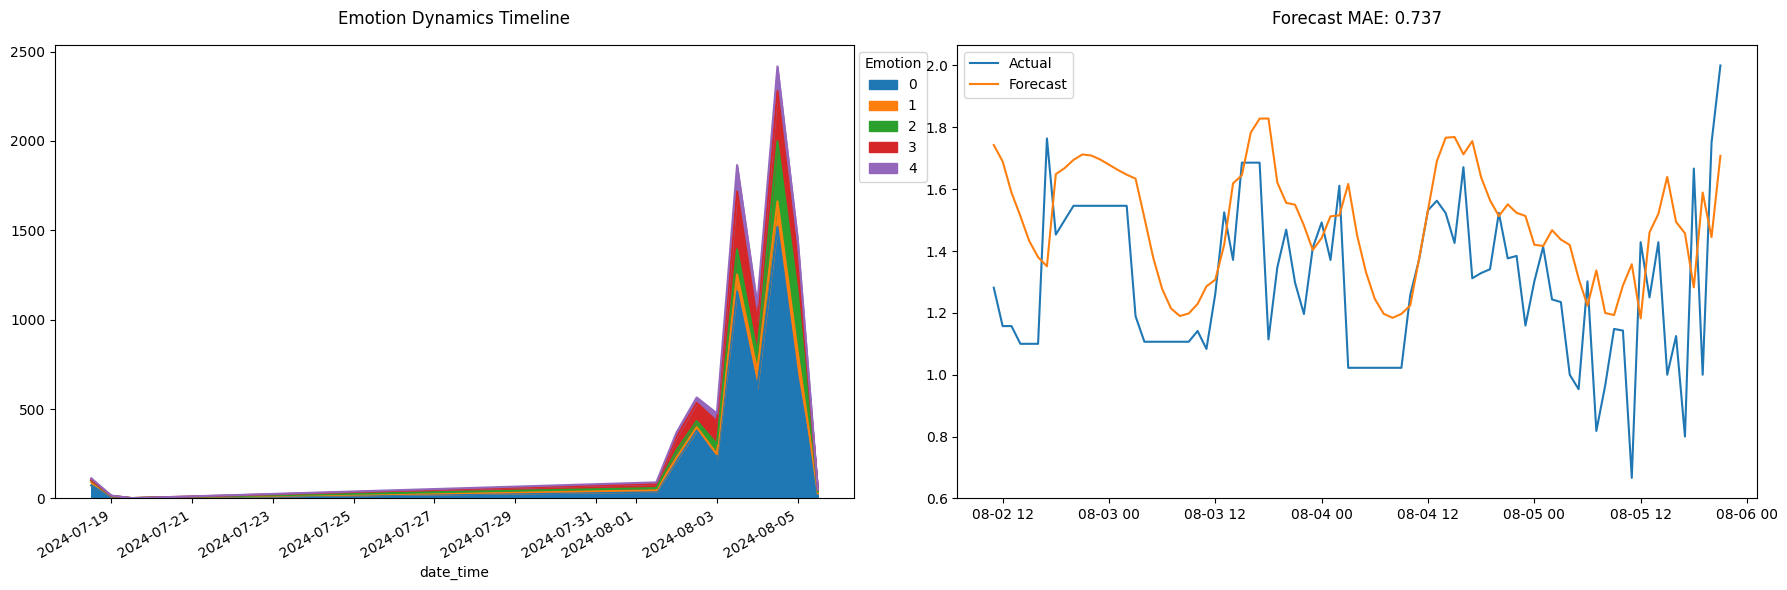


=== Part 3: Clusters & Associations ===


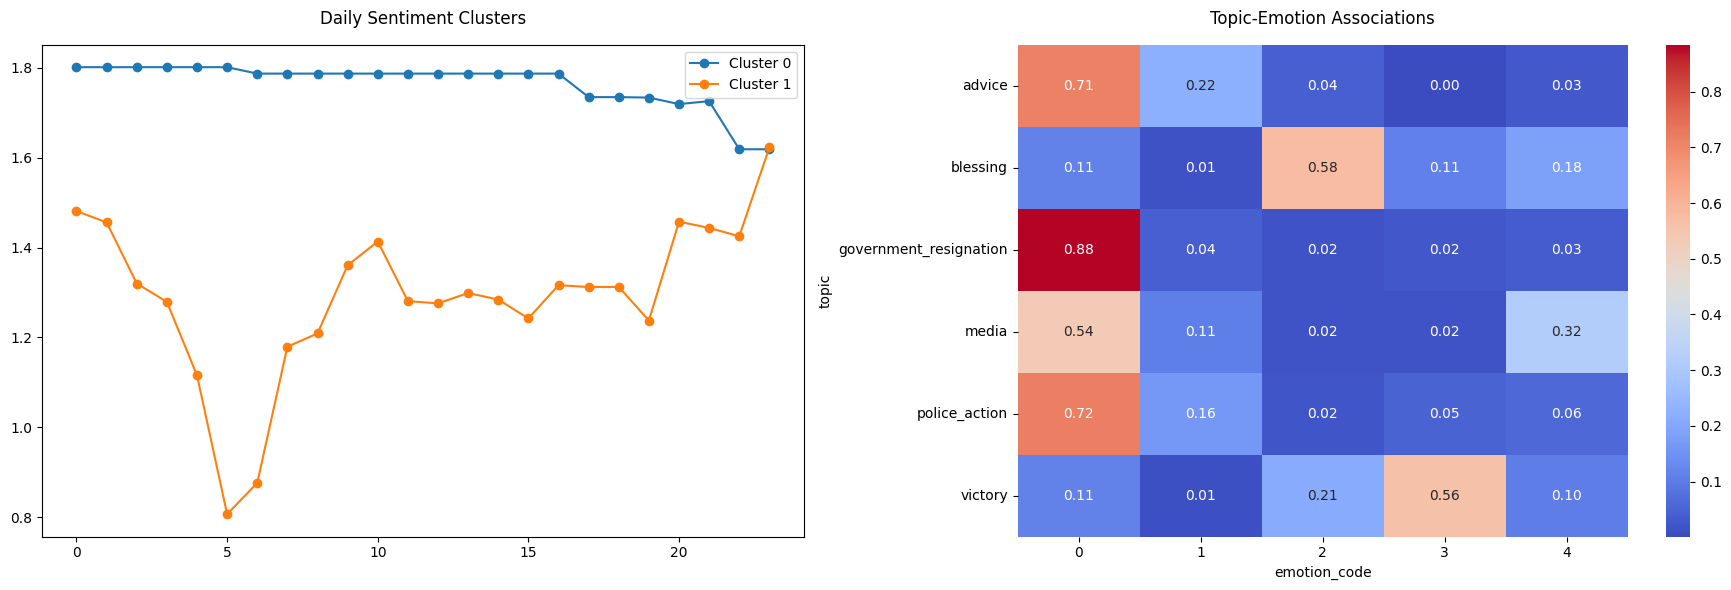


=== Evaluation Metrics ===
transition_entropy                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  1.26356
cluster_silhouette                                                                                                                                                                                                                                                                                                                                                              

In [6]:
# Third Visualization

def visualize_part3(df, centroids_orig, assoc_matrix):
    # Create figure with 2 plots + network video
    fig, axs = plt.subplots(1, 2, figsize=(18, 6))

    # Cluster Profiles
    for i, c in enumerate(centroids_orig):
        axs[0].plot(range(24), c, marker='o', label=f'Cluster {i}')
    axs[0].set_title("Daily Sentiment Clusters", pad=15)
    axs[0].legend()

    # Association Matrix
    sns.heatmap(assoc_matrix, cmap="coolwarm", ax=axs[1], annot=True, fmt=".2f")
    axs[1].set_title("Topic-Emotion Associations", pad=15)

    plt.tight_layout()
    plt.show()


def plot_topic_emotion_network(df):
    # Create a simple network
    G = nx.Graph()

    # emotion-topic pairs
    example_edges = [
        ('anger', 'government_resignation'),
        ('joy', 'victory'),
        ('neutral','blessing'),
        ('hope', 'advice'),
        ('anxiety', 'police_action')
    ]
    G.add_edges_from(example_edges)

    pos = nx.spring_layout(G, seed=42)

    fig, ax = plt.subplots(figsize=(8, 6))

    def update(num):
        ax.clear()
        nx.draw(G, pos, with_labels=True, node_color='skyblue', edge_color='gray', node_size=1500, ax=ax)
        ax.set_title(f"Network Frame {num + 1}")

    ani = animation.FuncAnimation(fig, update, frames=10, interval=1000, repeat=True)
    return ani

    # Show network animation
    ani = plot_topic_emotion_network(df)
    ani.save('network.mp4')


# Execution Pipeline
if __name__ == "__main__":

    # Generate components
    trans_matrix = create_emotion_transition_matrix(df)
    correlation = analyze_topic_emotion_association(df)
    evaluation = comprehensive_evaluation(df)

    # Run visualizations in sequence
    print("\n=== Part 1: Temporal Patterns ===")
    visualize_part1(df)

    print("\n=== Part 2: Emotion Dynamics ===")
    visualize_part2(df)

    print("\n=== Part 3: Clusters & Associations ===")
    visualize_part3(df, centroids_orig, correlation['association_matrix'])  # Pass required arguments
    # Show metrics separately
    print("\n=== Evaluation Metrics ===")
    print(pd.DataFrame([evaluation]).T.to_string(header=False))

/usr/local/lib/python3.11/dist-packages/networkx/drawing/nx_pylab.py:457: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  node_collection = ax.scatter(


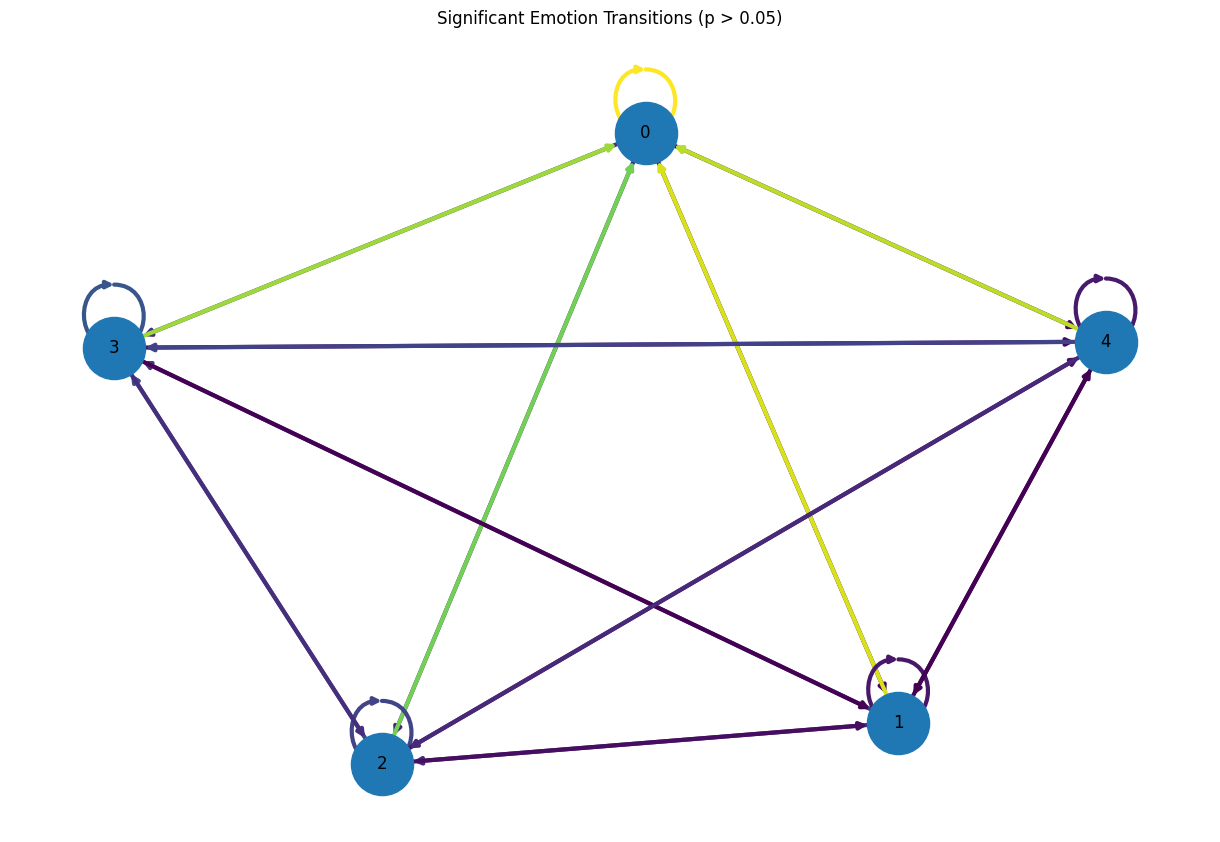

In [7]:
def plot_emotion_network(trans_matrix, threshold=0.05):
    """Interactive network diagram of significant transitions"""
    import networkx as nx

    G = nx.DiGraph()
    for src in trans_matrix.index:
        for dst in trans_matrix.columns:
            prob = trans_matrix.loc[src, dst]
            if prob > threshold:
                G.add_edge(src, dst, weight=prob,
                          label=f"{prob:.2f}")

    pos = nx.spring_layout(G, seed=42)
    plt.figure(figsize=(12,8))
    nx.draw(G, pos, with_labels=True,
           node_size=2000,
           edge_color=[d['weight'] for _,_,d in G.edges(data=True)],
           width=3,
           cmap=plt.cm.Reds)
    plt.title("Significant Emotion Transitions (p > 0.05)")
    plt.show()

# Usage
plot_emotion_network(trans_matrix)

In [8]:
# Transition Statistical Testing

def test_transition_significance(trans_matrix):
    """Chi-square test for transition significance"""
    results = {}

    # Get observed frequencies (convert probabilities to counts)
    # Assuming total transitions per emotion = 100 for demonstration
    observed = (trans_matrix * 100).astype(int)  # Replace 100 with actual counts if available

    for emotion in trans_matrix.index:
        # Create contingency table for current emotion
        em_observed = observed.loc[emotion].values
        total = em_observed.sum()

        # Expected frequencies (uniform distribution)
        expected = np.full_like(em_observed, total/len(em_observed))

        # Chi-square test
        chi2, p, _, _ = chi2_contingency([em_observed, expected])
        results[emotion] = p

    return pd.Series(results)

# Usage
transition_pvals = test_transition_significance(trans_matrix)
print("Transition Significance p-values:\n", transition_pvals)

Transition Significance p-values:
 0    7.619014e-08
1    1.230539e-06
2    5.844981e-05
3    3.250840e-06
4    2.959679e-06
dtype: float64


  Preparing metadata (setup.py) ... done
  DEPRECATION: Building 'autograd-gamma' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'autograd-gamma'. Discussion can be found at https://github.com/pypa/pip/issues/6334
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4030 sha256=fc5150b8af6b103253794d9ca004faff25d2c03aea6ea9fa114179f49241f1b3
  Stored in directory: /root/.cache/pip/wheels/8b/67/f4/2caaae2146198dcb824f31a303833b07b14a5ec863fb3acd7b
Successfully built autograd-gamma
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [lifelines]


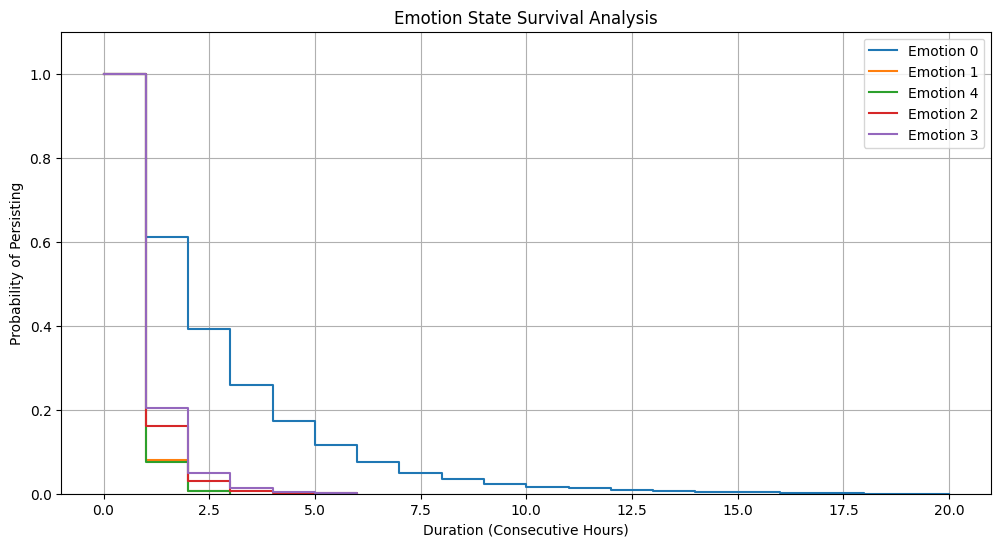

In [9]:
!pip install lifelines
from lifelines import KaplanMeierFitter

def emotion_survival_analysis(df):
    """Analyze emotion state durations with proper grouping"""
    df = df.sort_index()
    df['emotion_change'] = df['emotion_code'].ne(df['emotion_code'].shift()).cumsum()
    df['duration'] = df.groupby('emotion_change').cumcount() + 1
    kmf = KaplanMeierFitter()
    plt.figure(figsize=(12, 6))
    for emotion in df['emotion_code'].unique():
        mask = df['emotion_code'] == emotion
        kmf.fit(df['duration'][mask], label=f"Emotion {emotion}")
        kmf.plot_survival_function(ci_show=False)

    plt.title("Emotion State Survival Analysis")
    plt.xlabel("Duration (Consecutive Hours)")
    plt.ylabel("Probability of Persisting")
    plt.ylim(0, 1.1)
    plt.grid(True)
    plt.show()

emotion_survival_analysis(df)

In [10]:
X = SimpleImputer(strategy='mean').fit_transform(profiles)
X_scaled = StandardScaler().fit_transform(X)

kmeans = KMeans(n_clusters=2, random_state=42).fit(X_scaled)
sil_score = silhouette_score(X_scaled, kmeans.labels_)
cluster_counts = pd.Series(kmeans.labels_).value_counts().sort_index()

clust_df = pd.DataFrame({
    'Silhouette Score': [sil_score, sil_score],
    '# Days in Cluster': cluster_counts.values
}, index=['Cluster 0','Cluster 1'])

print(clust_df)

           Silhouette Score  # Days in Cluster
Cluster 0          0.640446                 14
Cluster 1          0.640446                  5
